<a href="https://colab.research.google.com/github/bhuvan-420/AI-Powered-Task-Management-System/blob/main/ola_driver_attrition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
upload =files.upload()

Saving ola_driver_scaler.csv to ola_driver_scaler.csv


In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from datetime import datetime

from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, confusion_matrix
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
import xgboost as xgb

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

# 1. Load dataset
df = pd.read_csv("/content/ola_driver_scaler.csv")
print(df.head())

   Unnamed: 0    MMM-YY  Driver_ID   Age  Gender City  Education_Level  \
0           0  01/01/19          1  28.0     0.0  C23                2   
1           1  02/01/19          1  28.0     0.0  C23                2   
2           2  03/01/19          1  28.0     0.0  C23                2   
3           3  11/01/20          2  31.0     0.0   C7                2   
4           4  12/01/20          2  31.0     0.0   C7                2   

   Income Dateofjoining LastWorkingDate  Joining Designation  Grade  \
0   57387      24/12/18             NaN                    1      1   
1   57387      24/12/18             NaN                    1      1   
2   57387      24/12/18        03/11/19                    1      1   
3   67016      11/06/20             NaN                    2      2   
4   67016      11/06/20             NaN                    2      2   

   Total Business Value  Quarterly Rating  
0               2381060                 2  
1               -665480                 

# Observations on Shape of Data

In [3]:
df.shape


(19104, 14)

# data types of all **collumns**

In [4]:
df.dtypes


,0
Unnamed: 0,int64
MMM-YY,object
Driver_ID,int64
Age,float64
Gender,float64
City,object
Education_Level,int64
Income,int64
Dateofjoining,object
LastWorkingDate,object


# Convert categorical variables to 'category' dtype

In [5]:
cat_cols = ["Gender", "City", "Education_Level", "Joining Designation", "Grade"]

for col in cat_cols:
    df[col] = df[col].astype('category')


# Convert date **columns**

In [6]:
df["MMM-YY"] = pd.to_datetime(df["MMM-YY"], errors='coerce')
df["Dateofjoining"] = pd.to_datetime(df["Dateofjoining"], errors='coerce')
df["LastWorkingDate"] = pd.to_datetime(df["LastWorkingDate"], errors='coerce')

# Missing Value **Detection**

In [7]:
df.isnull().sum()

,0
Unnamed: 0,0
MMM-YY,0
Driver_ID,0
Age,61
Gender,52
City,0
Education_Level,0
Income,0
Dateofjoining,0
LastWorkingDate,17488


# Statistical **Summary**

In [8]:
df.describe(include='all')


,Unnamed: 0,MMM-YY,Driver_ID,Age,Gender,City,Education_Level,Income,Dateofjoining,LastWorkingDate,Joining Designation,Grade,Total Business Value,Quarterly Rating
count,19104.000000,19104,19104.000000,19043.000000,19052.0,19104,19104.0,19104.000000,19104,1616,19104.0,19104.0,1.910400e+04,19104.000000
unique,NaN,NaN,NaN,NaN,2.0,29,3.0,NaN,NaN,NaN,5.0,5.0,NaN,NaN
top,NaN,NaN,NaN,NaN,0.0,C20,1.0,NaN,NaN,NaN,1.0,2.0,NaN,NaN
freq,NaN,NaN,NaN,NaN,11074.0,1008,6864.0,NaN,NaN,NaN,9831.0,6627.0,NaN,NaN
mean,9551.500000,2019-12-11 02:09:29.849246464,1415.591133,34.668435,NaN,NaN,NaN,65652.025126,2018-04-28 20:52:54.874371840,2019-12-21 20:59:06.534653696,NaN,NaN,5.716621e+05,2.008899
min,0.000000,2019-01-01 00:00:00,1.000000,21.000000,NaN,NaN,NaN,10747.000000,2013-04-01 00:00:00,2018-12-31 00:00:00,NaN,NaN,-6.000000e+06,1.000000
25%,4775.750000,2019-06-01 00:00:00,710.000000,30.000000,NaN,NaN,NaN,42383.000000,2016-11-29 12:00:00,2019-06-06 00:00:00,NaN,NaN,0.000000e+00,1.000000
50%,9551.500000,2019-12-01 00:00:00,1417.000000,34.000000,NaN,NaN,NaN,60087.000000,2018-09-12 00:00:00,2019-12-20 12:00:00,NaN,NaN,2.500000e+05,2.000000
75%,14327.250000,2020-07-01 00:00:00,2137.000000,39.000000,NaN,NaN,NaN,83969.000000,2019-11-05 00:00:00,2020-07-03 00:00:00,NaN,NaN,6.997000e+05,3.000000
max,19103.000000,2020-12-01 00:00:00,2788.000000,58.000000,NaN,NaN,NaN,188418.000000,2020-12-28 00:00:00,2020-12-28 00:00:00,NaN,NaN,3.374772e+07,4.000000


# Univariate **Analysis**

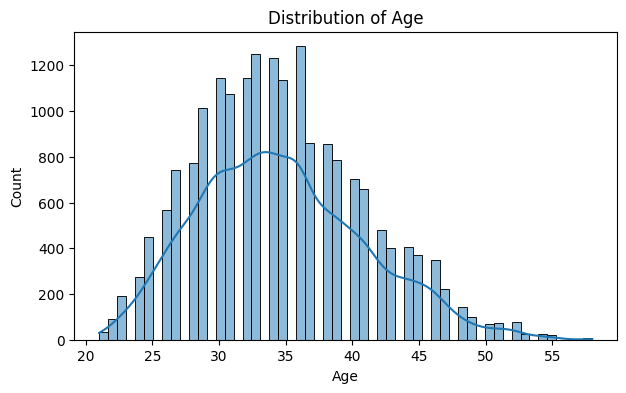

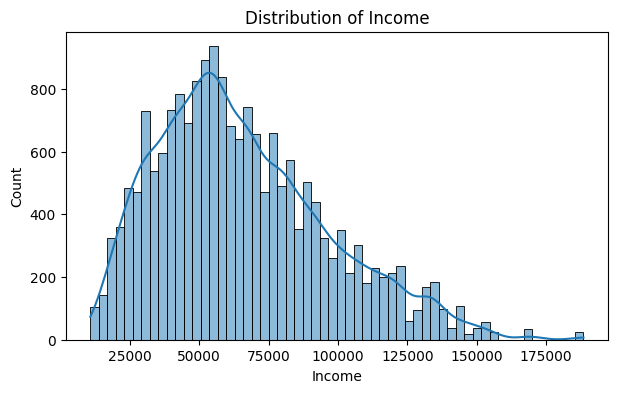

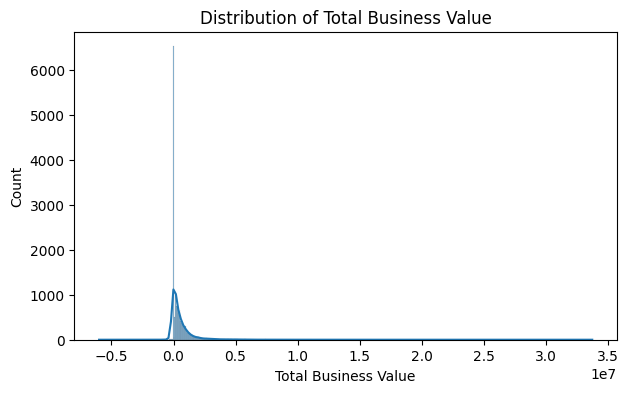

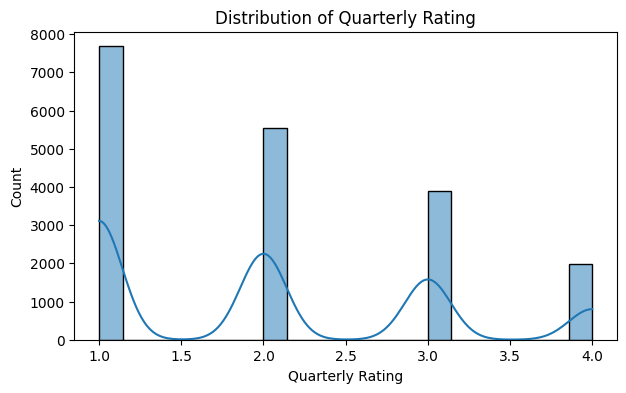

In [9]:
cont_cols = ["Age", "Income", "Total Business Value", "Quarterly Rating"]

for col in cont_cols:
    plt.figure(figsize=(7,4))
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribution of {col}")
    plt.show()


# 2.	Categorical Variables (Countplots) :

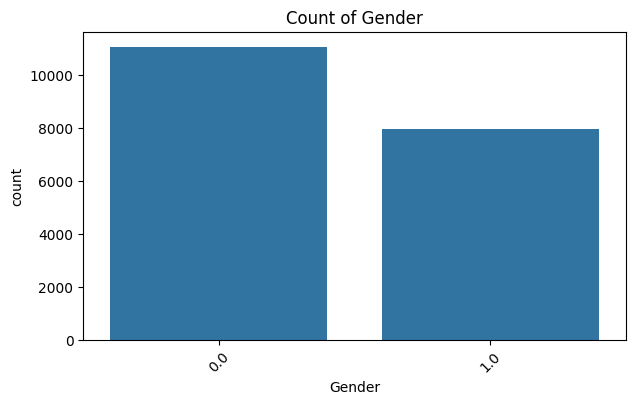

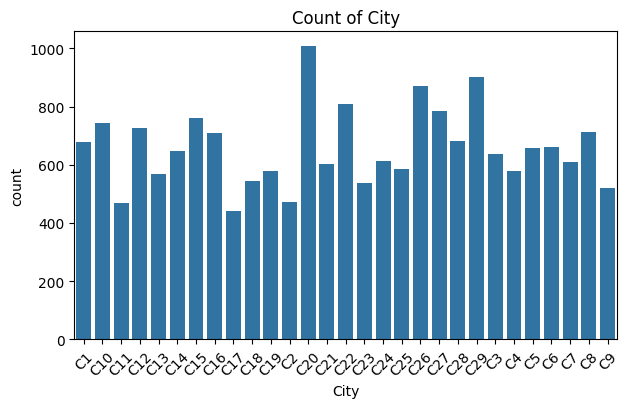

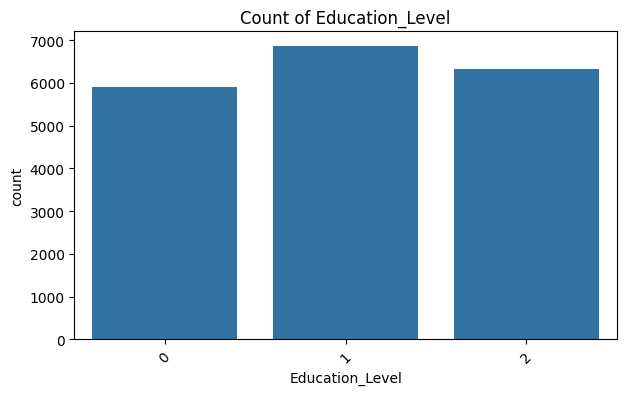

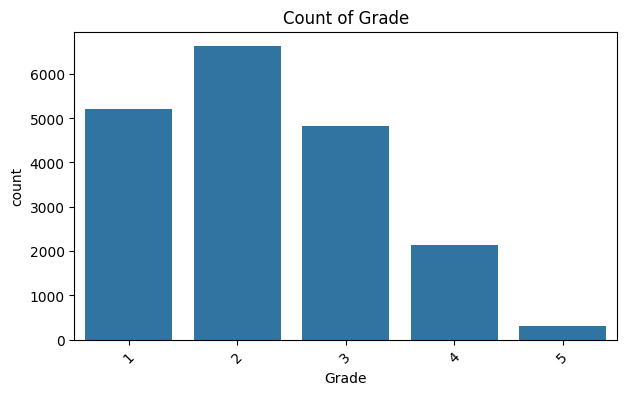

In [10]:
cat_cols = ["Gender", "City", "Education_Level", "Grade"]

for col in cat_cols:
    plt.figure(figsize=(7,4))
    sns.countplot(data=df, x=col)
    plt.title(f"Count of {col}")
    plt.xticks(rotation=45)
    plt.show()


# 1.	Income vs Business Value :

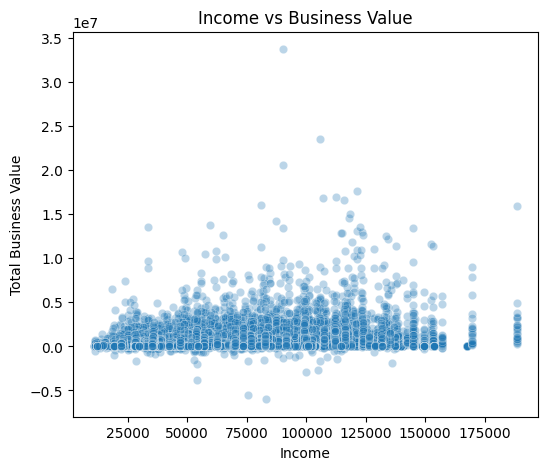

In [11]:
plt.figure(figsize=(6,5))
sns.scatterplot(data=df, x="Income", y="Total Business Value", alpha=0.3)
plt.title("Income vs Business Value")
plt.show()


# Age vs Attrition (using LastWorkingDate)

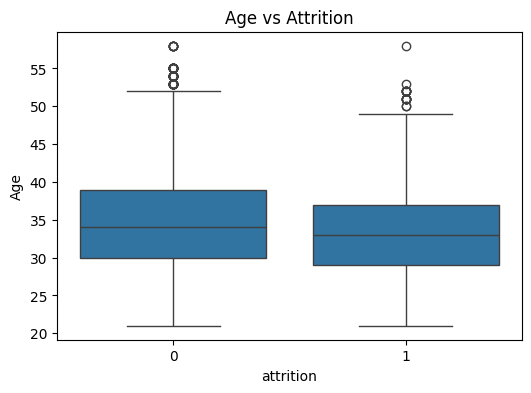

In [12]:
df["attrition"] = df["LastWorkingDate"].notna().astype(int)

plt.figure(figsize=(6,4))
sns.boxplot(data=df, x="attrition", y="Age")
plt.title("Age vs Attrition")
plt.show()


# Income vs **Attrition**

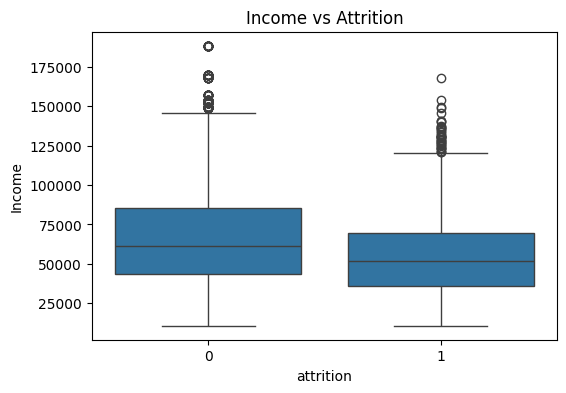

In [13]:
plt.figure(figsize=(6,4))
sns.boxplot(data=df, x="attrition", y="Income")
plt.title("Income vs Attrition")
plt.show()


# Quarterly Rating vs Attrition

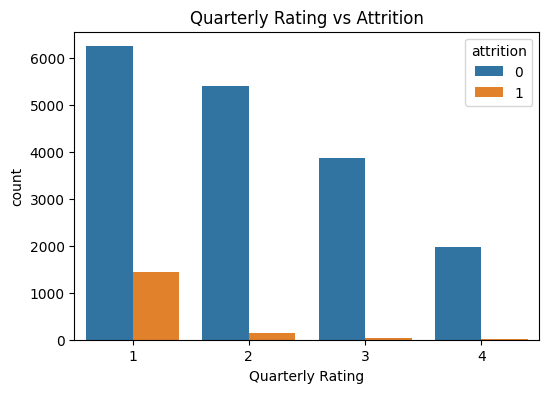

In [14]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="Quarterly Rating", hue="attrition")
plt.title("Quarterly Rating vs Attrition")
plt.show()


# City vs Attrition

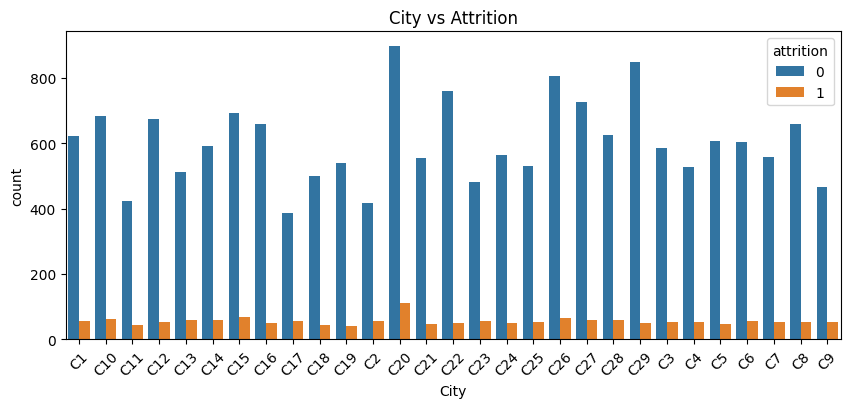

In [15]:
plt.figure(figsize=(10,4))
sns.countplot(data=df, x="City", hue="attrition")
plt.title("City vs Attrition")
plt.xticks(rotation=45)
plt.show()


# **2.Data Preprocessing ?**
	KNN Imputation
	Feature Engineering
	Class Imbalance treatment
	Standardization
	Encoding


Final dataset shape: (2381, 12)
Numeric Columns: ['Age', 'Gender', 'Education_Level', 'Income', 'Quarterly Rating', 'Total Business Value', 'Grade', 'Quarterly_Rating_Increase', 'Income_Increase']
Categorical Columns: ['City']
Training shape after SMOTE: (2422, 38)
Test shape: (596, 38)

==================== RANDOM FOREST RESULTS ====================
              precision    recall  f1-score   support

           0       0.68      0.58      0.63       191
           1       0.81      0.87      0.84       405

    accuracy                           0.78       596
   macro avg       0.75      0.73      0.73       596
weighted avg       0.77      0.78      0.77       596

ROC AUC: 0.809165535518066

==================== XGBOOST RESULTS ====================
              precision    recall  f1-score   support

           0       0.70      0.51      0.59       191
           1       0.79      0.90      0.84       405

    accuracy                           0.77       596
   macro avg    

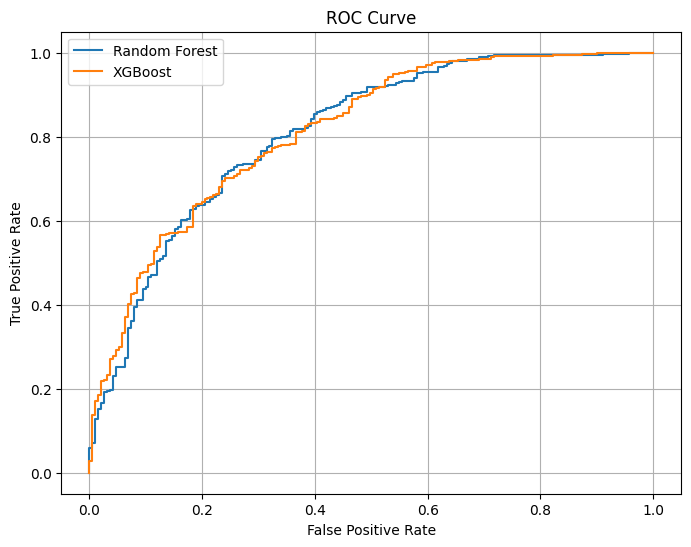

In [17]:
# ============================================================
# GOOGLE COLAB – OLA DRIVER ATTRITION MODEL
# ============================================================

# --------- INSTALL LIBRARIES (Colab Missing Packages) ---------
!pip install imbalanced-learn xgboost

# --------- IMPORT LIBRARIES ---------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score, roc_curve
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier


# ============================================================
# STEP 1: LOAD DATA
# ============================================================

df = pd.read_csv("/content/ola_driver_scaler.csv")


# ============================================================
# STEP 2: CLEANING & FEATURE ENGINEERING
# ============================================================

# Convert date columns
df['Dateofjoining'] = pd.to_datetime(df['Dateofjoining'], errors='coerce')
df['LastWorkingDate'] = pd.to_datetime(df['LastWorkingDate'], errors='coerce')
df['MMM-YY'] = pd.to_datetime(df['MMM-YY'], errors='coerce')

# Target: 1 = driver left Ola
df['target'] = df['LastWorkingDate'].notnull().astype(int)

# Sort to calculate increases correctly
df = df.sort_values(by=['Driver_ID', 'MMM-YY'])

# Quarterly Rating Increase
df['Quarterly_Rating_Increase'] = df.groupby('Driver_ID')['Quarterly Rating'].diff().apply(lambda x: 1 if x>0 else 0)
df['Quarterly_Rating_Increase'] = df['Quarterly_Rating_Increase'].fillna(0)

# Income Increase
df['Income_Increase'] = df.groupby('Driver_ID')['Income'].diff().apply(lambda x: 1 if x>0 else 0)
df['Income_Increase'] = df['Income_Increase'].fillna(0)

# Aggregate to Driver_ID level
agg_funcs = {
    'Age': 'mean',
    'Gender': 'first',
    'City': 'first',
    'Education_Level': 'first',
    'Income': 'mean',
    'Quarterly Rating': 'mean',
    'Total Business Value': 'sum',
    'Grade': 'mean',
    'Quarterly_Rating_Increase': 'max',
    'Income_Increase': 'max',
    'target': 'max'
}

df_final = df.groupby('Driver_ID').agg(agg_funcs).reset_index()

print("Final dataset shape:", df_final.shape)


# ============================================================
# STEP 3: SPLIT X AND y
# ============================================================

X = df_final.drop(columns=['target', 'Driver_ID'])
y = df_final['target']

numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = X.select_dtypes(include=['object']).columns

print("Numeric Columns:", numeric_cols.tolist())
print("Categorical Columns:", categorical_cols.tolist())


# ============================================================
# STEP 4: PREPROCESSING PIPELINE
# ============================================================

num_transformer = Pipeline(steps=[
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, numeric_cols),
        ('cat', cat_transformer, categorical_cols)
    ]
)

# FULL PIPELINE WITH SMOTE
pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42))
])


# ============================================================
# STEP 5: TRAIN–TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

X_train_res, y_train_res = pipeline.fit_resample(X_train, y_train)
X_test_trans = pipeline.named_steps['preprocessor'].transform(X_test)

print("Training shape after SMOTE:", X_train_res.shape)
print("Test shape:", X_test_trans.shape)


# ============================================================
# STEP 6: BAGGING MODEL (Random Forest)
# ============================================================

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight='balanced',
    random_state=42
)

rf.fit(X_train_res, y_train_res)
rf_pred = rf.predict(X_test_trans)

print("\n==================== RANDOM FOREST RESULTS ====================")
print(classification_report(y_test, rf_pred))
print("ROC AUC:", roc_auc_score(y_test, rf.predict_proba(X_test_trans)[:, 1]))


# ============================================================
# STEP 7: BOOSTING MODEL (XGBoost)
# ============================================================

xgb = XGBClassifier(
    learning_rate=0.05,
    max_depth=5,
    n_estimators=300,
    subsample=0.9,
    colsample_bytree=0.9,
    eval_metric='logloss',
    random_state=42
)

xgb.fit(X_train_res, y_train_res)
xgb_pred = xgb.predict(X_test_trans)

print("\n==================== XGBOOST RESULTS ====================")
print(classification_report(y_test, xgb_pred))
print("ROC AUC:", roc_auc_score(y_test, xgb.predict_proba(X_test_trans)[:, 1]))


# ============================================================
# STEP 8: ROC CURVE FOR BOTH MODELS
# ============================================================

rf_probs = rf.predict_proba(X_test_trans)[:, 1]
xgb_probs = xgb.predict_proba(X_test_trans)[:, 1]

rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probs)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_probs)

plt.figure(figsize=(8, 6))
plt.plot(rf_fpr, rf_tpr, label="Random Forest")
plt.plot(xgb_fpr, xgb_tpr, label="XGBoost")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()

# **Model building ? 1 Ensemble - Bagging Algorithm 1 Ensemble - Boosting Algorithm**

# 1. Ensemble – Bagging Algorithm (Random Forest)

In [21]:
# ============================================================
# 1. BAGGING MODEL: RANDOM FOREST CLASSIFIER
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

# Build Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42
)

# Train the model
rf_model.fit(X_train_res, y_train_res)

# Predictions
rf_pred = rf_model.predict(X_test_trans)
rf_prob = rf_model.predict_proba(X_test_trans)[:, 1]

# Evaluation
print("======== RANDOM FOREST (Bagging) ========")
print(classification_report(y_test, rf_pred))
print("ROC AUC Score:", roc_auc_score(y_test, rf_prob))


======== RANDOM FOREST (Bagging) ========
              precision    recall  f1-score   support

           0       0.65      0.58      0.61       191
           1       0.81      0.86      0.83       405

    accuracy                           0.77       596
   macro avg       0.73      0.72      0.72       596
weighted avg       0.76      0.77      0.76       596

ROC AUC Score: 0.8119320018098378


# 2.Ensemble – Boosting Algorithm (XGBoost)

In [22]:
# ============================================================
# 2. BOOSTING MODEL: XGBOOST CLASSIFIER
# ============================================================

from xgboost import XGBClassifier

# Build XGBoost model
xgb_model = XGBClassifier(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.9,
    colsample_bytree=0.9,
    eval_metric='logloss',
    random_state=42
)

# Train the model
xgb_model.fit(X_train_res, y_train_res)

# Predictions
xgb_pred = xgb_model.predict(X_test_trans)
xgb_prob = xgb_model.predict_proba(X_test_trans)[:, 1]

# Evaluation
print("======== XGBOOST (Boosting) ========")
print(classification_report(y_test, xgb_pred))
print("ROC AUC Score:", roc_auc_score(y_test, xgb_prob))


======== XGBOOST (Boosting) ========
              precision    recall  f1-score   support

           0       0.68      0.51      0.58       191
           1       0.79      0.89      0.84       405

    accuracy                           0.77       596
   macro avg       0.74      0.70      0.71       596
weighted avg       0.76      0.77      0.75       596

ROC AUC Score: 0.8072522784564671


# **PLOT ROC CURVE TOGETHER **

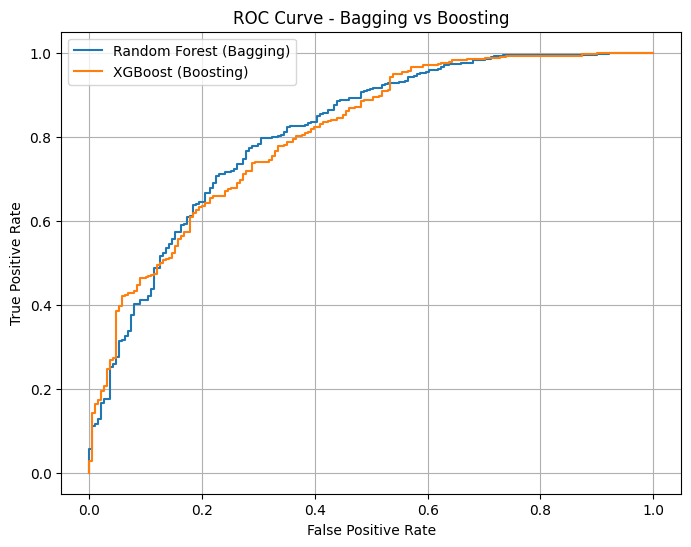

In [23]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

# Compute ROC curve
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_prob)

# Plot
plt.figure(figsize=(8, 6))
plt.plot(rf_fpr, rf_tpr, label='Random Forest (Bagging)')
plt.plot(xgb_fpr, xgb_tpr, label='XGBoost (Boosting)')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Bagging vs Boosting")
plt.legend()
plt.grid()
plt.show()


# 1. ROC–AUC Curve

ROC AUC Score (Random Forest): 0.812


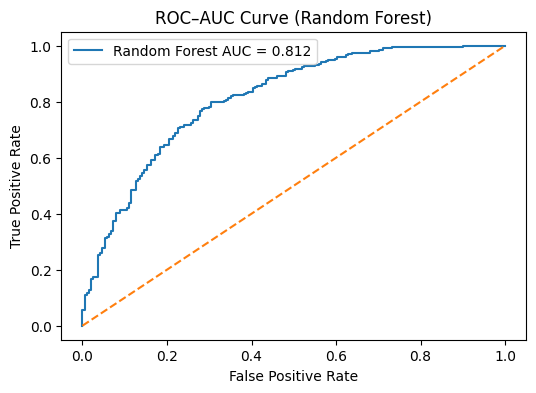

In [25]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Predict probabilities using the Random Forest model
y_prob = rf_model.predict_proba(X_test_trans)[:, 1]

# ROC values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# AUC score
auc_score = roc_auc_score(y_test, y_prob)
print(f"ROC AUC Score (Random Forest): {auc_score:.3f}")

# Plot ROC curve
plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f"Random Forest AUC = {auc_score:.3f}")
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC–AUC Curve (Random Forest)")
plt.legend()
plt.show()

# 2. Classification Report

In [28]:
from sklearn.metrics import classification_report

print("Classification Report (Random Forest):\n")
print(classification_report(y_test, rf_pred))

Classification Report (Random Forest):

              precision    recall  f1-score   support

           0       0.65      0.58      0.61       191
           1       0.81      0.86      0.83       405

    accuracy                           0.77       596
   macro avg       0.73      0.72      0.72       596
weighted avg       0.76      0.77      0.76       596



# Confusion Matrix

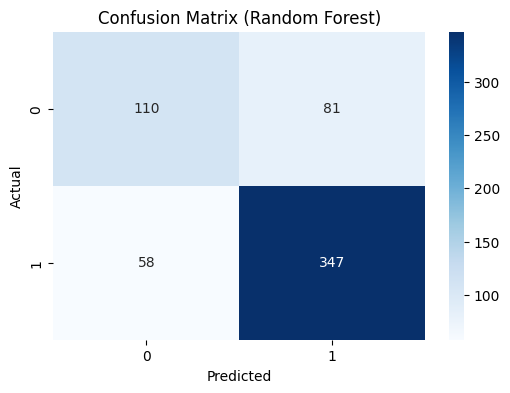

In [30]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, rf_pred) # Changed y_pred to rf_pred

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (Random Forest)") # Added model name to title
plt.show()